In [2]:
!pip install optuna

  Obtaining dependency information for optuna from https://files.pythonhosted.org/packages/90/e5/7c5e8cdda8c9f0cd8aca0a376dee9cff6b8c30692cf614960d9e80f59689/optuna-5.0.0-py3-none-any.whl.metadata
  Obtaining dependency information for alembic>=1.5.0 from https://files.pythonhosted.org/packages/11/3c/8740f5b4e1bd57333e4f84265b9b6363da4f7cf70f5622dd1e2fde7a0bd5/alembic-1.20.1-py3-none-any.whl.metadata
  Obtaining dependency information for colorlog from https://files.pythonhosted.org/packages/d4/19/0b6647bf5e331521e55d2b63bfbdc210bd9cd605189273f03614a05f702d/colorlog-6.12.0-py3-none-any.whl.metadata
  Obtaining dependency information for sqlalchemy>=1.4.2 from https://files.pythonhosted.org/packages/0d/33/108f557dba8278bb910b76437b3f93fed9a6ade4e01379dd435ba330ddd6/sqlalchemy-2.1.8-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for Mako from https://files.pythonhosted.org/packages/6d/a0/053d6af3e8f871e0073b4a36732d9e65be77a72e5434c31b94f6af78a6bb/mako-1.4.3-py3-no

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import optuna
import os
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

# Load the Final Feature Store
project_folder = r"C:\Users\Harshitha\Downloads\Project spy"
merged_df = pd.read_parquet(os.path.join(project_folder, "final_features_2024.parquet"))

print(" Data Loaded Successfully.")
print(f"Total Rows: {len(merged_df):,}")

 Data Loaded Successfully.
Total Rows: 882,206


In [4]:
# Define Features (X) and Target (y)
features = ['zone_id', 'hour', 'day_of_week', 'month', 'is_weekend', 
            'lag_3h', 'lag_6h', 'lag_12h', 
            'HourlyDryBulbTemperature', 'HourlyPrecipitation', 'HourlyWindSpeed']

X = merged_df[features]
y = merged_df['demand_count']

# CHRONOLOGICAL SPLIT: Train on Jan-Sept, Test on Oct-Dec
train_mask = merged_df['pickup_hour'] < '2024-10-01'
test_mask = merged_df['pickup_hour'] >= '2024-10-01'

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print(f" Training Set: {X_train.shape[0]:,} rows (Jan - Sept)")
print(f" Testing Set:  {X_test.shape[0]:,} rows (Oct - Dec)")

 Training Set: 657,235 rows (Jan - Sept)
 Testing Set:  224,971 rows (Oct - Dec)


In [5]:
print("Training Random Forest Baseline ")
rf_model = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

rf_preds = rf_model.predict(X_test)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))
rf_mae = mean_absolute_error(y_test, rf_preds)

print(f" Random Forest Performance:")
print(f"    RMSE: {rf_rmse:.4f}")
print(f"    MAE:  {rf_mae:.4f}")

Training Random Forest Baseline 
 Random Forest Performance:
    RMSE: 11.1734
    MAE:  4.7346


In [6]:
print("Training XGBoost Baseline")
xgb_baseline = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42, n_jobs=-1)
xgb_baseline.fit(X_train, y_train)

xgb_preds = xgb_baseline.predict(X_test)

xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_preds))
xgb_mae = mean_absolute_error(y_test, xgb_preds)

print(f" XGBoost Baseline Performance:")
print(f"    RMSE: {xgb_rmse:.4f}")
print(f"   MAE:  {xgb_mae:.4f}")

Training XGBoost Baseline
 XGBoost Baseline Performance:
    RMSE: 11.9075
   MAE:  5.0660


In [7]:
print(" Starting Optuna Hyperparameter Optimization (this may take a few minutes)")

def objective(trial):
  
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 4, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'random_state': 42,
        'n_jobs': -1
    }

    model = xgb.XGBRegressor(**param)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    return rmse

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=20)

print("\n Optimization Complete!")
print(f"Best RMSE found: {study.best_value:.4f}")
print("Best Parameters found:")
for key, value in study.best_params.items():
    print(f"    {key}: {value}")

[I 2026-11-04 22:33:58,541] A new study created in memory with name: no-name-b88b20aa-be89-426a-852f-c527dbfbade1


 Starting Optuna Hyperparameter Optimization (this may take a few minutes)...


[I 2026-11-04 22:34:18,299] Trial 0 finished with value: 11.883507822975123 and parameters: {'n_estimators': 348, 'max_depth': 10, 'learning_rate': 0.19790223469847204, 'subsample': 0.8554737052375672, 'colsample_bytree': 0.8896727507080213}. Best is trial 0 with value: 11.883507822975123.
[I 2026-11-04 22:34:28,843] Trial 1 finished with value: 11.423628937238076 and parameters: {'n_estimators': 208, 'max_depth': 9, 'learning_rate': 0.12002508990640173, 'subsample': 0.6751831749993653, 'colsample_bytree': 0.9759797265148055}. Best is trial 1 with value: 11.423628937238076.
[I 2026-11-04 22:34:43,913] Trial 2 finished with value: 11.229319574356557 and parameters: {'n_estimators': 473, 'max_depth': 5, 'learning_rate': 0.22150924464691563, 'subsample': 0.9826040016398223, 'colsample_bytree': 0.7363994288653521}. Best is trial 2 with value: 11.229319574356557.
[I 2026-11-04 22:34:49,289] Trial 3 finished with value: 12.01289374334374 and parameters: {'n_estimators': 135, 'max_depth': 5, 


 Optimization Complete!
Best RMSE found: 11.1139
Best Parameters found:
   • n_estimators: 484
   • max_depth: 6
   • learning_rate: 0.14218918181261556
   • subsample: 0.9573585418802172
   • colsample_bytree: 0.9042098330920597


In [9]:
# Train the final model using the best parameters found by Optuna
best_params = study.best_params
best_params['random_state'] = 42
best_params['n_jobs'] = -1

final_model = xgb.XGBRegressor(**best_params)
final_model.fit(X_train, y_train)

final_preds = final_model.predict(X_test)

final_rmse = np.sqrt(mean_squared_error(y_test, final_preds))
final_mae = mean_absolute_error(y_test, final_preds)

print(" FINAL OPTIMIZED XGBOOST PERFORMANCE")

print(f"RMSE: {final_rmse:.4f} (Improvement from Baseline: {((xgb_rmse - final_rmse)/xgb_rmse)*100:.1f}%)")
print(f"MAE:  {final_mae:.4f}")


 FINAL OPTIMIZED XGBOOST PERFORMANCE
RMSE: 11.1139 (Improvement from Baseline: 6.7%)
MAE:  4.6789


<Figure size 1000x600 with 0 Axes>

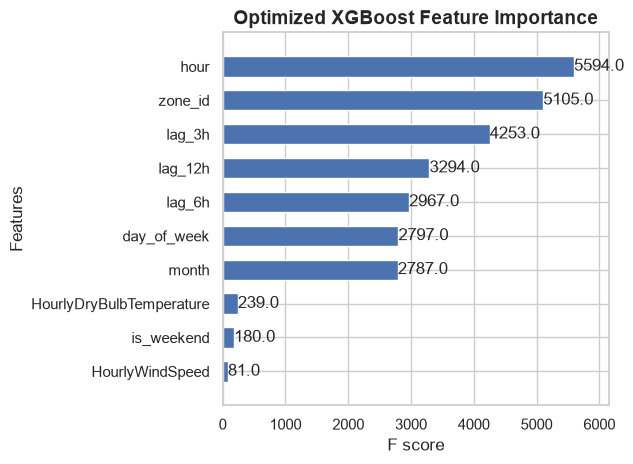

 INSIGHT: Lag features (past demand) and 'hour' are the strongest predictors. Weather features also contribute, proving our multi-modal fusion was successful.


In [10]:
plt.figure(figsize=(10, 6))
xgb.plot_importance(final_model, importance_type='weight', max_num_features=10, height=0.6)
plt.title('Optimized XGBoost Feature Importance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(project_folder, "week3_feature_importance.png"), dpi=150)
plt.show()

print(" INSIGHT: Lag features (past demand) and 'hour' are the strongest predictors. Weather features also contribute, proving our multi-modal fusion was successful.")

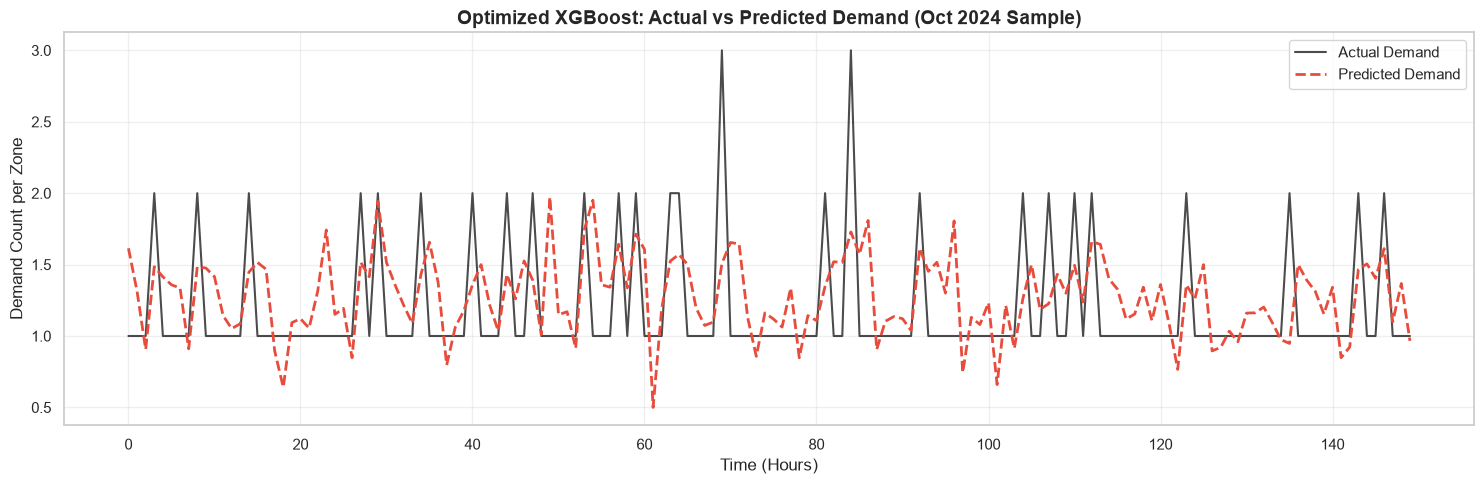

In [11]:
# Plot a sample of the test set (first 150 hours of October)
plt.figure(figsize=(15, 5))
plt.plot(y_test.values[:150], label='Actual Demand', color='black', alpha=0.7)
plt.plot(final_preds[:150], label='Predicted Demand', color='#E74C3C', linestyle='--', linewidth=2)

plt.title('Optimized XGBoost: Actual vs Predicted Demand (Oct 2024 Sample)', fontsize=14, fontweight='bold')
plt.xlabel('Time (Hours)')
plt.ylabel('Demand Count per Zone')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(project_folder, "week3_actual_vs_predicted.png"), dpi=150)
plt.show()

In [16]:
# Save the model using the core booster (avoids sklearn compatibility bug)
final_model.get_booster().save_model(
    os.path.join(project_folder, "xgboost_optimized_model.json")
)

# Save predictions for the upcoming Ablation Study & SHAP analysis
predictions_df = pd.DataFrame({'actual': y_test, 'predicted': final_preds})
predictions_df.to_csv(
    os.path.join(project_folder, "xgb_predictions.csv"), index=False
)

print("Model and predictions saved successfully.")

Model and predictions saved successfully.
